# RJMCMC
Checking data stationarity by implementing RJMCMC analysis with change points.


In [1]:
from torch.utils.data import ConcatDataset
import glob
import xarray as xr

basin_files = glob.glob("Caravan-nc/timeseries/netcdf/camels/*.nc")
basin_files = basin_files[:25]

In [2]:
import numpy as np
from scipy.stats import pearson3

def calc_return_periods(ds):
    '''
    Takes in nc ds and treats it using B17b return period fitting 
    Returns dict (water_year, return period of max streamflow event that year)
    '''

    annual_max = ds['streamflow'].groupby('water_year').max('date')
    annual_max = annual_max.where(annual_max > 0, drop=True)  # remove zero-flow years
    log_annual_max = np.log10(annual_max)

    # annual_max = ds['streamflow'].groupby('water_year').max('date')
    # log_annual_max = np.log10(annual_max) # For the B17b fitting procedure

    params = pearson3.fit(log_annual_max)
    skew, mu, sig = params # shape location scale of the fit

    # Calculate the return years by evaluating the fit PDF distribution
    p3cdf = pearson3.cdf(log_annual_max, skew, loc=mu, scale=sig)
    return_periods_list = 1/(1-p3cdf)

    # I want these to live in a dictionary
    return_periods = dict(zip(annual_max['water_year'].values, return_periods_list))

    return return_periods

def add_water_year(ds):
    '''
    Water year is defined as Oct 1 to  Sep 30.
    Oct, Nov, Dec are labelled as regular year + 1
    '''
    t = ds['date']
    water_year = t.dt.year + (t.dt.month >= 10)
    new_ds = ds.assign_coords(water_year=water_year)
    return new_ds

In [3]:
from torch.utils.data import ConcatDataset

multibasin_annual_maxima = [] # One entry for each basin

for basin_file in basin_files:
    ds = xr.open_dataset(basin_file)

    # Get rid of NaN values
    ds = ds.dropna(dim='date', 
               subset=['streamflow', 
                       'total_precipitation_sum',
                       'temperature_2m_mean',
                       'surface_net_solar_radiation_mean',
                       'surface_net_thermal_radiation_mean',
                       'dewpoint_temperature_2m_mean',
                       'u_component_of_wind_10m_mean',
                       'v_component_of_wind_10m_mean'], # From which features
                 how='any') # Any of the subsets

    # Water year
    ds = add_water_year(ds)

    # Put the max streamflow values into a list
    basin_annual_maxima = ds['streamflow'].groupby('water_year').max('date')
    basin_annual_maxima = basin_annual_maxima.where(basin_annual_maxima > 0, drop=True)  # remove zero-flow years
    basin_annual_maxima_dict = dict(zip(basin_annual_maxima['water_year'].values, basin_annual_maxima.values))
    multibasin_annual_maxima.append(basin_annual_maxima_dict)


In [4]:
import numpy as np
import random
from scipy.stats import poisson, norm, halfnorm, uniform
from scipy.special import gammaln, logsumexp
from tqdm import tqdm
from copy import deepcopy
from itertools import chain

class RJMCMC:

    def __init__(self,
                        multibasin_annual_maxima,
                        k_lam = 0.5, k_max = 10,
                        gam_mu = 0.3, gam_std = 0.6,
                        sig_mu = 0, sig_std = 1,
                        min_seg = 2,
                 ):
        '''
        Parameters
        ----------
        multibasin_annual_maxima : list of dict
            One dict per basin mapping water_year (int) -> annual maximum streamflow (float).
        k_lam : float
            Poisson prior rate on number of change points k ~ Poisson(k_lam).
        k_max : int
            Maximum number of change points allowed.
        gam_mu, gam_std : float
            Mean and std of the Normal prior on LP3 skewness gamma. Defaults from
            Bulletin 17C cross-basin RMSE (Martins & Stedinger 2000).
        sig_mu, sig_std : float
            Location and scale of the HalfNormal prior on LP3 std sigma (must be positive).
        min_seg : int
            Minimum number of data points per segment. Set to 2 (just prevents
            empty/degenerate segments); the prior on k does the actual regularisation.
        '''
        self.multibasin_annual_maxima =  [list(basin_annual_maxima.values()) for basin_annual_maxima in multibasin_annual_maxima]
        self.multibasin_key_years = [list(basin_annual_maxima.keys()) for basin_annual_maxima in multibasin_annual_maxima]

        self.k_lam = k_lam
        self.k_max = k_max
        self.gam_mu = gam_mu
        self.gam_std = gam_std
        self.sig_mu = sig_mu
        self.sig_std = sig_std
        self.min_seg = min_seg

        vals = [v for d in multibasin_annual_maxima for v in d.values()]
        self.mu_max = max(vals)
        self.mu_min = min(vals)
        self.mu_mean = np.mean(vals)
        self.mu_std = np.std(vals)

        self.prior_k = poisson(self.k_lam)
        self.prior_gam = norm(self.gam_mu, self.gam_std)
        self.prior_sig = halfnorm(self.sig_mu, self.sig_std)
        self.prior_mu = uniform(self.mu_min, self.mu_max)

        self.calc_c()

    def calc_c(self):
        '''
        Compute the scaling constant c that caps birth/death proposal probabilities
        at 0.9 across all k. Setting b_k and d_k proportional to min(1, p(k±1)/p(k))
        causes the prior ratio on k to cancel in the MH acceptance ratio (Green 1995).
        Stores result in self.c.
        '''
        k_vals = np.arange(0, self.k_max + 1)

        b_k = np.array([ min(1, self.prior_k.pmf(k+1)/self.prior_k.pmf(k)) 
                        if k<self.k_max else 0.0 for k in k_vals ])
        d_k = np.array([ min(1, self.prior_k.pmf(k-1)/self.prior_k.pmf(k)) 
                        if k>0 else 0.0 for k in k_vals ])
        
        self.c = 0.9/np.max(b_k + d_k)

    def _valid_split_positions(self, boundaries, n):
        '''
        Return all positions at which a new change point can be inserted such that
        both resulting segments have at least self.min_seg data points.
        '''
        positions = []
        for i in range(len(boundaries) - 1):
            left = boundaries[i]
            right = boundaries[i + 1]
            for pos in range(left + self.min_seg, right - self.min_seg + 1):
                positions.append(pos)
        return positions

    def log_likelihood(self,
                state,
                basin_annual_maxima
            ):
        '''
        LP3 log-likelihood for one basin under the current state.

        Parameters
        ----------
        state : list, length 4k+3
            Encodes k change points followed by (k+1) sets of LP3 parameters:
            [cp_1, ..., cp_k, mu_0, ..., mu_k, sig_0, ..., sig_k, gam_0, ..., gam_k]
            Change points are positional indices into basin_annual_maxima.
        basin_annual_maxima : list of float
            Annual maximum streamflows for a single basin, in water year order.

        Returns
        -------
        float
            Total log-likelihood summed across all k+1 segments.
        '''
        params = state
        k = (len(params) - 3) // 4

        change_points = [0] + params[0:k]
        mus = params[k:2*k+1]
        sigs= params[2*k+1:3*k+2]
        gams = params[3*k+2:4*k+3]

        # Split the stuff by change point
        segments = []
        for i in range(0, len(change_points)-1):
            start = change_points[i]
            end = change_points[i+1]
            segment = basin_annual_maxima[start:end]
            segments.append(segment)
        segments.append(basin_annual_maxima[change_points[-1]:])

        total_lnL = 0
        for idx in range(0,len(segments)):
            segment = segments[idx]
            n = len(segment)
            LN10 = np.log(10)
            mu = mus[idx]
            sig = sigs[idx]
            gam = gams[idx]

            alpha = 4 / (gam * gam)
            beta = (sig * gam) / 2
            chi = mu - ((2*sig)/gam)

            y = np.log10(segment)

            # Pearson III support: (y - chi)/beta > 0 for all data points.
            # If any point is outside the support, the density is zero → log-likelihood = -inf.
            if beta > 0 and np.any(y <= chi):
                return -np.inf
            if beta < 0 and np.any(y >= chi):
                return -np.inf

            segment_lnL = 0
            segment_lnL += -np.sum(np.log(segment))
            segment_lnL += -n*np.log(LN10) - n*gammaln(alpha)
            segment_lnL += (alpha-1) * np.sum(np.log(y - chi) if beta > 0 else np.log(chi - y))
            segment_lnL += -n * alpha * np.log(np.abs(beta))
            segment_lnL += (-1/beta) * np.sum(y - chi)

            total_lnL += segment_lnL

        return total_lnL

    
    def log_prior(self,
                        mu, sig, gam):
        '''
        Calculates the prior of a state or proposed state
        '''
        lnPi = 0

        lnPi += self.prior_mu.logpdf(mu)
        lnPi += self.prior_sig.logpdf(sig)
        lnPi += self.prior_gam.logpdf(gam)

        return lnPi
        
    def transition(self, state, basin_annual_maxima):
        '''
        MH transition to the next state in the chain for a single basin.

        Parameters
        ----------
        state : list, length 4k+3
            Current state encoding change points and LP3 parameters (see log_likelihood).
        basin_annual_maxima : list of float
            Annual maximum streamflows for this basin, in water year order.

        Returns
        -------
        next_state : list
            Proposed next state (accepted or current state if rejected).
        move_type : int
            0 = LP3 parameter update, 1 = change point position move,
            2 = birth (add change point), 3 = death (remove change point).
        accept : int
            1 if the proposed move was accepted, 0 otherwise.
        '''
        k = (len(state) - 3) // 4

        p_birth = self.c * min(1, self.prior_k.pmf(k+1)/self.prior_k.pmf(k)) \
                if k < self.k_max else 0.0
        p_death = self.c * min(1, self.prior_k.pmf(k-1)/self.prior_k.pmf(k)) \
                if k > 0 else 0.0

        if k == 0:
            p_theta = 1.0 - p_birth - p_death
            p_pos = 0.0
        else:
            p_theta = 0.5 * (1.0 - p_birth - p_death)
            p_pos = 0.5 * (1.0 - p_birth - p_death)

        assert np.isclose(p_theta + p_pos + p_birth + p_death, 1.0), \
            "Move probabilities do not sum to 1."

        # POSSIBLE MOVE TYPES:
        # 0 : p_theta = LP3 parameter update, with probability p_theta
        # 1 : p_pos   = change point position move, with probability p_pos
        # 2 : p_birth = birth move (add change point), with probability p_birth
        # 3 : p_death = death move (remove change point), with probability p_death

        move_type = np.random.choice(4, p=np.array([p_theta, p_pos, p_birth, p_death]))

        if move_type == 0:
            next_state, accept = self.theta_move(state, basin_annual_maxima)
        elif move_type == 1:
            next_state, accept = self.pos_move(state, basin_annual_maxima)  
        elif move_type == 2:
            next_state, accept = self.birth_move(state, basin_annual_maxima)  
        elif move_type == 3:
            next_state, accept = self.death_move(state, basin_annual_maxima)  
        else:
            raise ValueError("Invalid move type.")
        
        return next_state, move_type, accept

    def theta_move(self, state, basin_annual_maxima):
        '''
        This move changes the theta values of the one segment
        '''
        k = (len(state) - 3) // 4

        proposed_state = deepcopy(state)

        # choose which segment theta to alter
        # k changes means k+1 segments
        j = np.random.randint(0,k+1)

        # extract the segment theta
        change_points = [0] + state[0:k]
        current_mu = state[k:2*k+1][j]
        current_sig = state[2*k+1:3*k+2][j]
        current_gam = state[3*k+2:4*k+3][j]

        # propose new theta from the old one
        if j != k: # has not selected the final change point
            start = change_points[j]
            end = change_points[j+1]
            n_seg = end-start # len of segment
            segment = basin_annual_maxima[start:end]
        else:
            start = change_points[j]
            n_seg = len(basin_annual_maxima) - start
            segment = basin_annual_maxima[start:]

        # fall back to global std if segment is too small to have meaningful spread
        seg_std = np.std(np.log10(segment)) if n_seg > 1 else self.mu_std

        # theta prime
        proposed_mu = current_mu + np.random.normal(0, 0.5 * seg_std / np.sqrt(n_seg))
        proposed_sig = current_sig * np.exp(np.random.normal(0, 0.5 / np.sqrt(2 * n_seg)))
        proposed_gam = current_gam + np.random.normal(0, 0.5 * np.sqrt(6 / n_seg))

        proposed_state[k+j] = proposed_mu
        proposed_state[2*k+1+j] = proposed_sig
        proposed_state[3*k+2+j] = proposed_gam

        # likelihood and prior ratios (log)
        LnLR = self.log_likelihood(proposed_state, basin_annual_maxima) - self.log_likelihood(state, basin_annual_maxima)
        LnPiR = self.log_prior(proposed_mu, proposed_sig, proposed_gam) - self.log_prior(current_mu, current_sig, current_gam)
        LnCorrection = np.log(proposed_sig / current_sig) # because the sigma is multiplicative by an exp so the linearity is in log space
        
        # Acceptance prob
        log_accept_prob = LnLR + LnPiR + LnCorrection

        # Check if accept
        if np.log(np.random.uniform()) < log_accept_prob:
            accept = 1
            return proposed_state, accept
        else:
            accept = 0
            return state, accept

    def pos_move(self, 
                 state,
                 basin_annual_maxima):
        '''
        Choose a random change point and move it.
        This only calls if there is at least one change point.
        The change point is generated uniformly between its two neighbours,
        subject to both resulting segments having at least min_seg points.
        '''
        k = (len(state) - 3) // 4

        proposed_state = deepcopy(state)

        # choose which position to use
        j = np.random.randint(1, k+1)

        # Propose a new position
        change_points = state[0:k]
        s_jminus1 = change_points[j-2] if j>1 else 0
        s_j = change_points[j-1]
        s_jplus1 = state[j] if j<k else len(basin_annual_maxima)

        lo = s_jminus1 + self.min_seg
        hi = s_jplus1 - self.min_seg

        if hi < lo:
            return state, 0

        s_j_prime = np.random.randint(lo, hi + 1)
        proposed_state[j-1] = s_j_prime

        # likelihood and prior ratios (log)
        # prior ratio cancels because the parameters are constant
        # proposal ratio cancels because both directions draw uniformly over [lo, hi]
        LnLR = self.log_likelihood(proposed_state, basin_annual_maxima) - self.log_likelihood(state, basin_annual_maxima)

        log_accept_prob = LnLR

        # Check if accept
        if np.log(np.random.uniform()) < log_accept_prob:
            accept = 1
            return proposed_state, accept
        else:
            accept = 0
            return state, accept

    def birth_move(self,
                   state,
                   basin_annual_maxima):
        '''
        Create a new change point in a segment.
        Only positions where both resulting segments have >= min_seg points are considered.
        '''
        k = (len(state) - 3) // 4

        boundaries = [0] + state[0:k] + [len(basin_annual_maxima)]
        mus = state[k:2*k+1]
        sigs= state[2*k+1:3*k+2]
        gams = state[3*k+2:4*k+3]

        draw_list = self._valid_split_positions(boundaries, len(basin_annual_maxima))

        if len(draw_list) == 0:
            return state, 0

        proposed_change_point = np.random.choice(draw_list) # this is the new proposed change point

        # Find which segment the new change point falls in
        seg_idx = next(i for i in range(len(boundaries)-1)
                       if boundaries[i] < proposed_change_point < boundaries[i+1])

        n1 = proposed_change_point - boundaries[seg_idx]
        n2 = boundaries[seg_idx+1] - proposed_change_point
        n = n1 + n2

        # Choose new theta values for the two new segments via auxiliary variables u
        mu_j = mus[seg_idx]
        sig_j = sigs[seg_idx]
        gam_j = gams[seg_idx]

        eps = 1e-6
        u_mu = np.random.uniform(eps, 1-eps)
        u_sig = np.random.uniform(eps, 1-eps)
        u_gam = np.random.uniform(eps, 1-eps)

        mu_j_prime = mu_j - u_mu * (n2/n1) * sig_j      # preserves weighted arithmetic mean
        mu_jplus1_prime = mu_j + u_mu * sig_j

        sig_j_prime = sig_j * ((1-u_sig)/u_sig) ** (-(n2/n))  # preserves weighted geometric mean
        sig_jplus1_prime = sig_j_prime * ((1-u_sig)/u_sig)

        gam_j_prime = gam_j - u_gam * (n2/n1) * self.gam_std  # preserves weighted arithmetic mean
        gam_jplus1_prime = gam_j + u_gam * self.gam_std

        # Build proposed state
        new_change_points = sorted(state[0:k] + [proposed_change_point])
        new_mus = mus[:seg_idx] + [mu_j_prime, mu_jplus1_prime] + mus[seg_idx+1:]
        new_sigs = sigs[:seg_idx] + [sig_j_prime, sig_jplus1_prime] + sigs[seg_idx+1:]
        new_gams = gams[:seg_idx] + [gam_j_prime, gam_jplus1_prime] + gams[seg_idx+1:]

        proposed_state = new_change_points + new_mus + new_sigs + new_gams
        
        # Calculate the acceptance ratio
        LnLR = self.log_likelihood(proposed_state, basin_annual_maxima) - self.log_likelihood(state, basin_annual_maxima)
        LnPiR = (self.log_prior(mu_j_prime, sig_j_prime, gam_j_prime)
                 + self.log_prior(mu_jplus1_prime, sig_jplus1_prime, gam_jplus1_prime)
                 - self.log_prior(mu_j, sig_j, gam_j))
        LnProposalR = np.log(len(draw_list)) - np.log(k+1)
        LnJacobian = (2*np.log(n/n1)
                      + np.log(sig_j_prime) + np.log(sig_jplus1_prime)
                      - np.log(u_sig) - np.log(1-u_sig)
                      + np.log(self.gam_std))

        log_accept_prob = LnLR + LnPiR + LnProposalR + LnJacobian

        if np.log(np.random.uniform()) < log_accept_prob:
            return proposed_state, 1
        else:
            return state, 0

    def death_move(self,
                   state,
                   basin_annual_maxima):
        '''
        Select a change point for eradication.
        '''
        k = (len(state) - 3) // 4

        boundaries = [0] + state[0:k] + [len(basin_annual_maxima)]
        mus = state[k:2*k+1]
        sigs = state[2*k+1:3*k+2]
        gams = state[3*k+2:4*k+3]

        # Choose a change point to remove uniformly
        j = np.random.randint(0, k)  # index into state[0:k]
        seg_idx = j  # left segment index (j and j+1 are the two segments being merged)

        n1 = state[j] - boundaries[seg_idx]
        n2 = boundaries[seg_idx+2] - state[j]
        n = n1 + n2

        # Merge the two segments by inverting the split formulas
        mu_j_prime = mus[seg_idx]
        mu_jplus1_prime = mus[seg_idx+1]
        sig_j_prime = sigs[seg_idx]
        sig_jplus1_prime = sigs[seg_idx+1]
        gam_j_prime = gams[seg_idx]
        gam_jplus1_prime = gams[seg_idx+1]

        mu_j = (n1*mu_j_prime + n2*mu_jplus1_prime) / n
        sig_j = sig_j_prime**(n1/n) * sig_jplus1_prime**(n2/n)
        gam_j = (n1*gam_j_prime + n2*gam_jplus1_prime) / n

        # Build proposed state
        new_change_points = state[0:j] + state[j+1:k]
        new_mus = mus[:seg_idx] + [mu_j] + mus[seg_idx+2:]
        new_sigs = sigs[:seg_idx] + [sig_j] + sigs[seg_idx+2:]
        new_gams = gams[:seg_idx] + [gam_j] + gams[seg_idx+2:]

        proposed_state = new_change_points + new_mus + new_sigs + new_gams

        # Compute draw_list for the reverse birth move (from k-1 state),
        # using the same min_seg constraint as birth_move
        boundaries_km1 = [0] + new_change_points + [len(basin_annual_maxima)]
        draw_list_km1 = self._valid_split_positions(boundaries_km1, len(basin_annual_maxima))

        if len(draw_list_km1) == 0:
            return state, 0

        # Recover u_sig for the Jacobian
        u_sig = sig_jplus1_prime / (sig_j_prime + sig_jplus1_prime)

        # Calculate the acceptance ratio
        LnLR = self.log_likelihood(proposed_state, basin_annual_maxima) - self.log_likelihood(state, basin_annual_maxima)
        LnPiR = (self.log_prior(mu_j, sig_j, gam_j)
                 - self.log_prior(mu_j_prime, sig_j_prime, gam_j_prime)
                 - self.log_prior(mu_jplus1_prime, sig_jplus1_prime, gam_jplus1_prime))
        LnProposalR = np.log(k) - np.log(len(draw_list_km1))
        LnJacobian = -(2*np.log(n/n1)
                       + np.log(sig_j_prime) + np.log(sig_jplus1_prime)
                       - np.log(u_sig) - np.log(1-u_sig)
                       + np.log(self.gam_std))

        log_accept_prob = LnLR + LnPiR + LnProposalR + LnJacobian

        if np.log(np.random.uniform()) < log_accept_prob:
            return proposed_state, 1
        else:
            return state, 0

    def run_mcmc(self,
                 num_iter=100):
        """
        Run the RJMCMC algorithm for a specified number of iterations.

        Parameters
        ----------
        num_iter : int
            Number of MCMC iterations to perform.
        """
        # initialise one state per basin with k=0, using sample stats as starting values
        states = []
        for basin_data in self.multibasin_annual_maxima:
            log_data = np.log10(basin_data)
            mu0 = np.mean(log_data)
            sig0 = np.std(log_data)
            gam0 = self.gam_mu
            states.append([mu0, sig0, gam0])

        self.chain = [states]
        move_type_attempt_count = {0:0, 1:0, 2:0, 3:0}
        move_type_accept_count = {0:0, 1:0, 2:0, 3:0}

        # evolve chain for specified number of iterations
        for i in tqdm(range(num_iter)):
            next_states = []
            for state, basin_data in zip(self.chain[-1], self.multibasin_annual_maxima):
                next_state, move_type, accepted = self.transition(state, basin_data)
                next_states.append(next_state)
                move_type_attempt_count[move_type] += 1
                move_type_accept_count[move_type] += accepted
            self.chain.append(next_states)

        # print a summary of the move types and acceptance fractions
        total_attempts = sum(move_type_attempt_count.values())
        for i in range(4):
            f = move_type_attempt_count[i] / total_attempts
            a = move_type_accept_count[i] / max(1, move_type_attempt_count[i])
            m = ['Theta change', 'Position change', 'Birth', 'Death'][i]
            print(f"{m} moves attempted {100*f:.1f}% of the time",
                  f"with an acceptance fraction of {a:.3f}")


def main():
    sampler = RJMCMC(multibasin_annual_maxima)
    sampler.calc_c()
    sampler.run_mcmc(num_iter=1200)
    return sampler


if __name__ == "__main__":
    sampler = main()


100%|██████████| 1200/1200 [00:56<00:00, 21.09it/s]

Theta change moves attempted 59.2% of the time with an acceptance fraction of 0.644
Position change moves attempted 0.4% of the time with an acceptance fraction of 0.111
Birth moves attempted 34.4% of the time with an acceptance fraction of 0.013
Death moves attempted 6.0% of the time with an acceptance fraction of 0.073


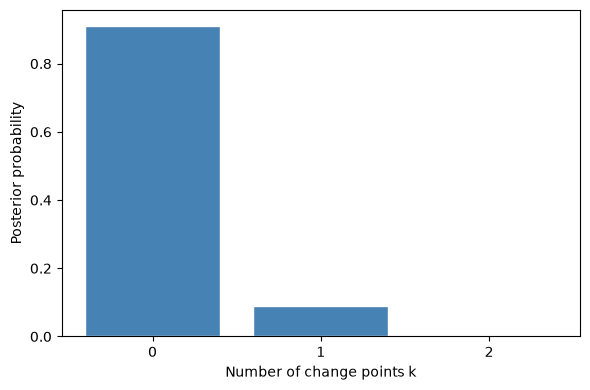

In [7]:
import matplotlib.pyplot as plt

burnin = 200  # iterations to discard

k_samples = []
for states in sampler.chain[burnin:]:
    for state in states:
        k = (len(state) - 3) // 4
        k_samples.append(k)

k_samples = np.array(k_samples)
k_vals = np.arange(0, k_samples.max() + 2)
counts = np.bincount(k_samples, minlength=len(k_vals))
posterior = counts / counts.sum()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(k_vals, posterior[:len(k_vals)], color='steelblue', edgecolor='white')
ax.set_xlabel('Number of change points k')
ax.set_ylabel('Posterior probability')
ax.set_xticks(k_vals)
plt.tight_layout()
plt.show()


In [6]:
lengths = [len(x) for x in multibasin_annual_maxima]
np.mean(lengths)

np.float64(34.92)